In [102]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [103]:
# Loading the housing price dataset (assuming the file name is "housing_price.csv")
df = pd.read_csv("C:/Users/Meli/Desktop/Ironhack/Lab1/lab-eda-univariate/amz_uk_price_prediction_dataset.csv")
df.head(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [104]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [106]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [107]:
df.stars

0          4.7
1          4.7
2          4.7
3          4.7
4          4.6
          ... 
2443646    0.0
2443647    0.0
2443648    0.0
2443649    4.3
2443650    4.5
Name: stars, Length: 2443651, dtype: float64

# Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.



In [78]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


## Are there categories where being a best-seller is more prevalent?

In [79]:
# Example crosstab_result provided
data = {
    'False': [247, 4065, 245, 1696, 251, 243, 234, 17559, 1939, 246],
    'True': [1, 2, 5, 1, 3, 7, 5, 213, 20, 0]
}
index = [
    '3D Printers', '3D Printing & Scanning', 'Abrasive & Finishing Products', 
    'Action Cameras', 'Adapters', 'Wind Instruments', 'Window Treatments', 
    'Women', 'Women\'s Sports & Outdoor Shoes', 'eBook Readers & Accessories'
]
crosstab_result = pd.DataFrame(data, index=index)

# Step 1: Calculate the total count of items in each category
total_counts = crosstab_result.sum(axis=1)

# Step 2: Calculate the count of best-sellers in each category
best_seller_counts = crosstab_result['True']

# Step 3: Calculate the proportion of best-sellers for each category
proportion_best_sellers = best_seller_counts / total_counts

# Step 4: Sort the categories based on the proportion of best-sellers in descending order
sorted_proportion = proportion_best_sellers.sort_values(ascending=False)

# Display the sorted proportions
print(sorted_proportion)

Wind Instruments                  0.028000
Window Treatments                 0.020921
Abrasive & Finishing Products     0.020000
Women                             0.011985
Adapters                          0.011811
Women's Sports & Outdoor Shoes    0.010209
3D Printers                       0.004032
Action Cameras                    0.000589
3D Printing & Scanning            0.000492
eBook Readers & Accessories       0.000000
dtype: float64


## Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [80]:
from scipy.stats import chi2_contingency

# Chi-square test for 'MSZoning' and 'SaleCondition'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(79.58020146215587, 1.9581459394006088e-13)

In [81]:
# the best-seller distribution is not independent of the product category, they are related!!!.

## Compute Cramér's V to understand the strength of association between best-seller status and category.


In [82]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")

0.054308204933055645

## Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

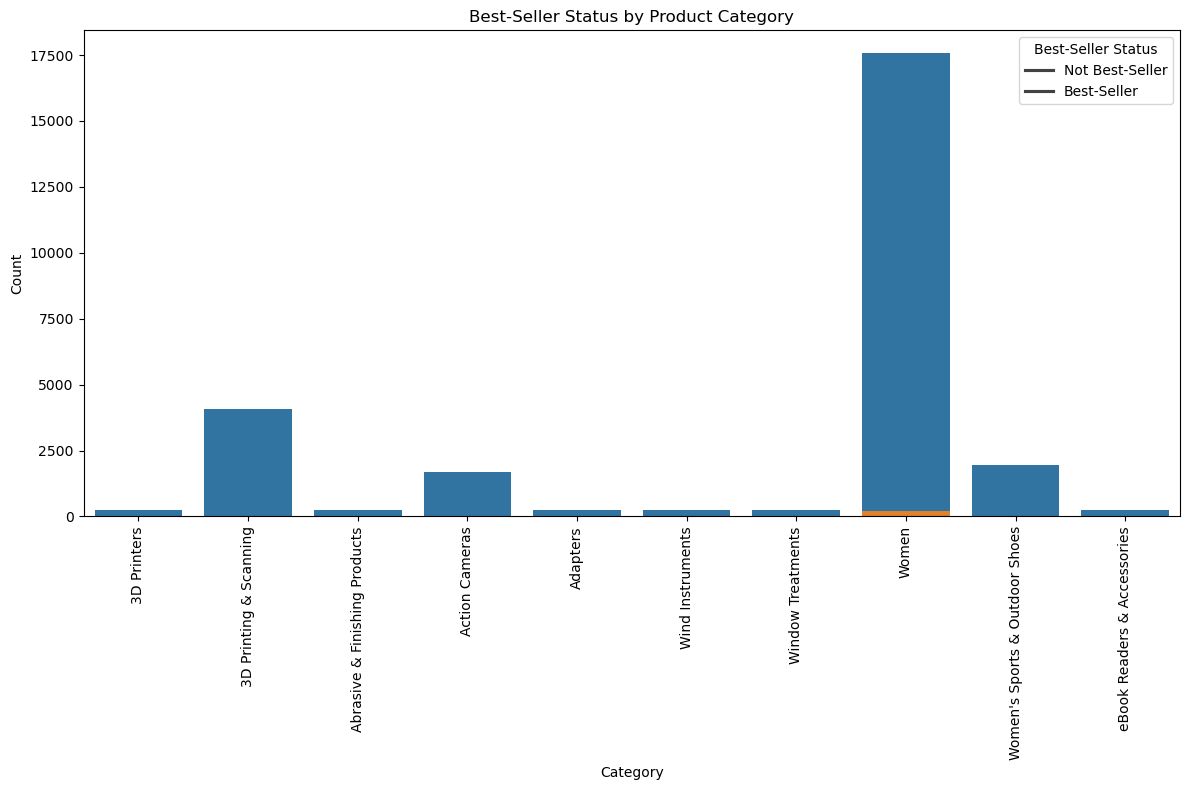

In [83]:
crosstab_result = pd.DataFrame(data, index=index)

# Step 1: Prepare the data for plotting
crosstab_result.reset_index(inplace=True)
crosstab_result_melted = crosstab_result.melt(id_vars='index', var_name='isBestSeller', value_name='count')
crosstab_result_melted.rename(columns={'index': 'category'}, inplace=True)

# Step 2: Plot the stacked bar chart
plt.figure(figsize=(12, 8))
sns.barplot(data=crosstab_result_melted, x='category', y='count', hue='isBestSeller', dodge=False)

# Step 3: Customize the plot
plt.xticks(rotation=90)
plt.xlabel('Category')
plt.ylabel('Count')
plt.title('Best-Seller Status by Product Category')
plt.legend(title='Best-Seller Status', labels=['Not Best-Seller', 'Best-Seller'])

# Show the plot
plt.tight_layout()
plt.show()

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

In [84]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return outliers

# Example DataFrame for demonstration
data = {
    'category': ['3D Printers', '3D Printing & Scanning', 'Abrasive & Finishing Products', 'Action Cameras', 
                 'Adapters', 'Wind Instruments', 'Window Treatments', 'Women', 'Women\'s Sports & Outdoor Shoes', 
                 'eBook Readers & Accessories'],
    'price': [1000, 500, 150, 300, 50, 250, 200, 100, 75, 350]  # Example prices
}

df = pd.DataFrame(data)

In [85]:
# Identify outliers in the 'price' column
data_series = df['price']
outliers = tukeys_test_outliers(data_series)

# Filter out the outliers from the DataFrame
df_filtered = df.drop(outliers.index)

# Display the filtered DataFrame
print("Filtered DataFrame without outliers:")
print(df_filtered)

Filtered DataFrame without outliers:
                         category  price
1          3D Printing & Scanning    500
2   Abrasive & Finishing Products    150
3                  Action Cameras    300
4                        Adapters     50
5                Wind Instruments    250
6               Window Treatments    200
7                           Women    100
8  Women's Sports & Outdoor Shoes     75
9     eBook Readers & Accessories    350


## Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categori
es.

<Axes: xlabel='price', ylabel='category'>

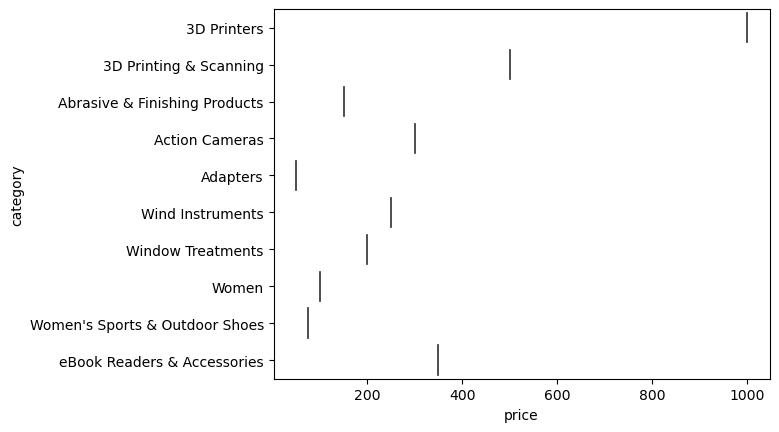

In [86]:
sns.violinplot(data = df, x= "price", y = "category",palette="coolwarm", hue='price', legend=False)

In [ ]:
# the product category 3d printers tends to have the highest median price

## Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

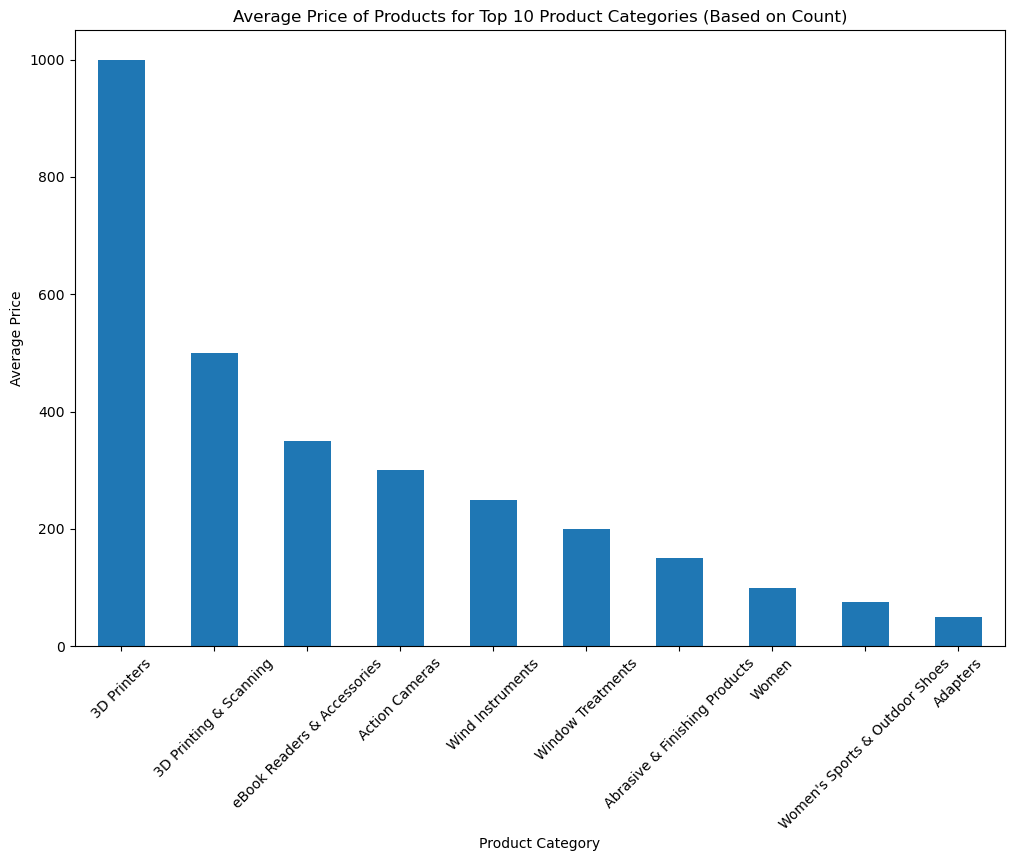

The product category with the highest average price is 3D Printers with an average price of 1000.00.


In [88]:
# Step 1: Identify the top 10 product categories based on count
top_categories = df['category'].value_counts().nlargest(10).index

# Step 2: Calculate the average price for these top 10 categories
top_categories_avg_price = df[df['category'].isin(top_categories)].groupby('category')['price'].mean().sort_values(ascending=False)

# Step 3: Create a bar chart to visualize the average prices
plt.figure(figsize=(12, 8))
top_categories_avg_price.plot(kind='bar')
plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.title('Average Price of Products for Top 10 Product Categories (Based on Count)')
plt.xticks(rotation=45)
plt.show()

# Display which product category commands the highest average price
highest_avg_price_category = top_categories_avg_price.idxmax()
highest_avg_price = top_categories_avg_price.max()
print(f'The product category with the highest average price is {highest_avg_price_category} with an average price of {highest_avg_price:.2f}.')

## Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

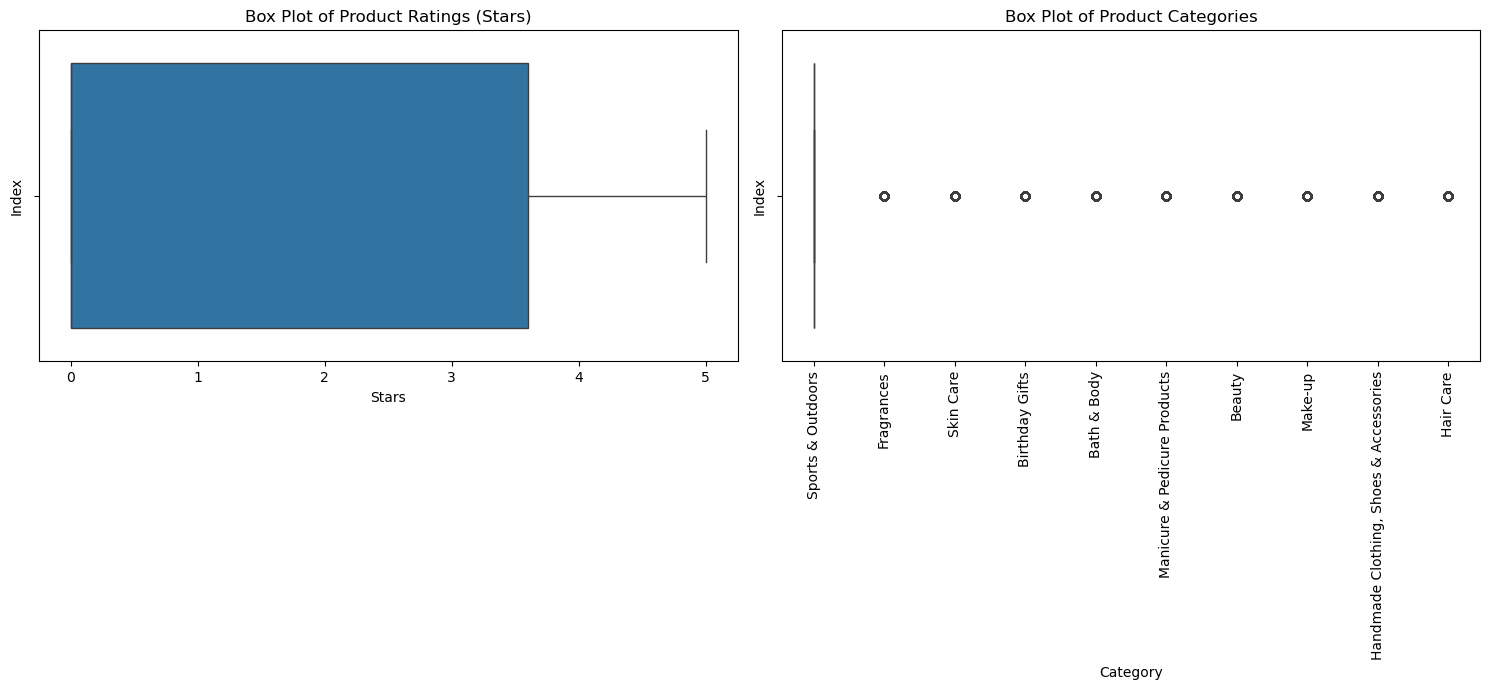

In [108]:
"""revisar lab eda univariate la parte de ratings and stars """

# Get the top 10 categories by count
top_categories = df['category'].value_counts().nlargest(10).index

# Filter the DataFrame to include only these top 10 categories
filtered_df = df[df['category'].isin(top_categories)]

# Create the subplots
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 7))

# Box plot of stars (Y = "index", x = "stars")
sns.boxplot(x=filtered_df['stars'], ax=axes[0])
axes[0].set_title('Box Plot of Product Ratings (Stars)')
axes[0].set_xlabel('Stars')
axes[0].set_ylabel('Index')

# Box plot of category (Y = "index", x = "category")
sns.boxplot(x=filtered_df['category'], ax=axes[1])
axes[1].set_title('Box Plot of Product Categories')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Index')
axes[1].tick_params(axis='x', rotation=90)

# Show the plot
plt.tight_layout()
plt.show()

## 

In [110]:
# Calculate the correlation coefficient between price and stars
df = pd.DataFrame(data)

# Calculate the correlation coefficient between price and stars
correlation = filtered_df['price'].corr(filtered_df['stars'])

print(f'The correlation coefficient between price and stars is {correlation:.2f}.')

The correlation coefficient between price and stars is -0.10.


## Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.

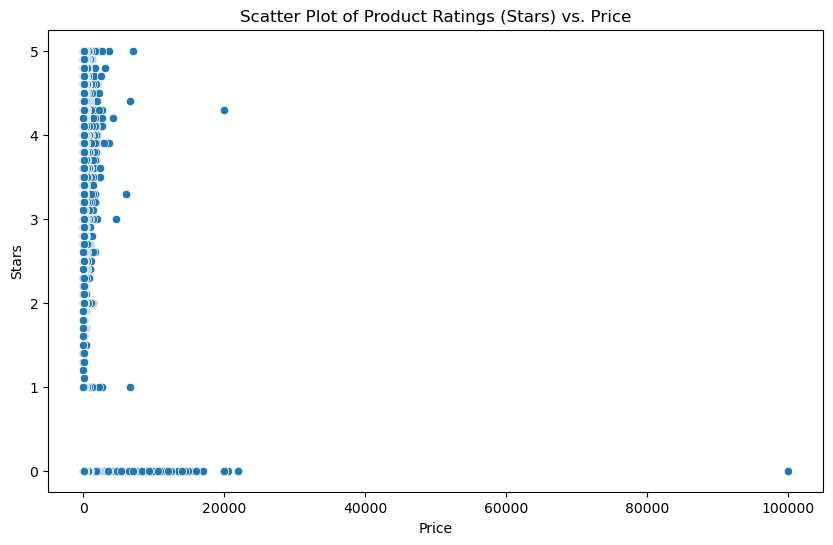

In [112]:
# Scatter plot of stars vs. price
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='stars', data=filtered_df)
plt.title('Scatter Plot of Product Ratings (Stars) vs. Price')
plt.xlabel('Price')
plt.ylabel('Stars')
plt.show()


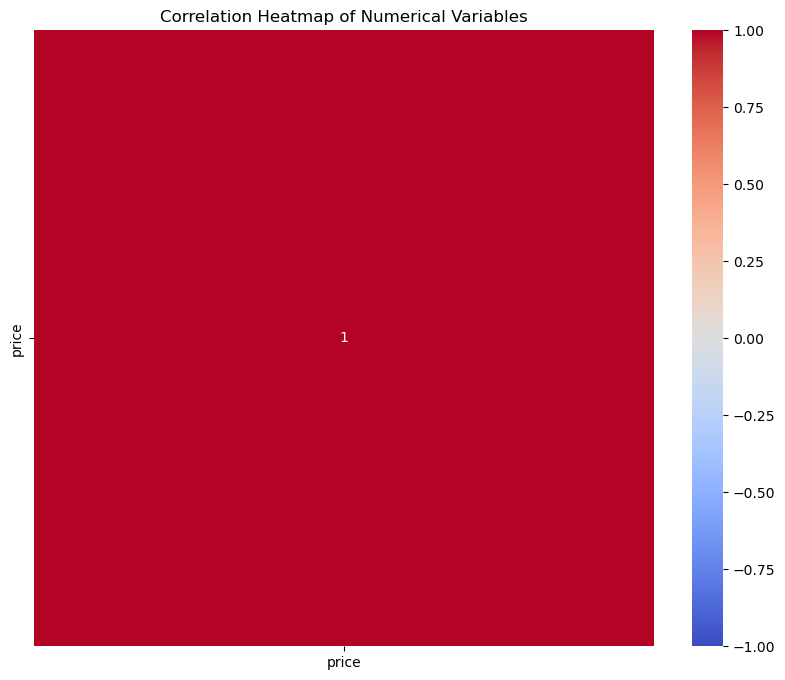

In [121]:

# Correlation heatmap for all numerical variables
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include='number')
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()